In [2]:
pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ------------------------------- -------- 6.6/8.2 MB 31.0 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 30.0 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 1.6/1.6 MB 22.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   -------------------------- ------------- 4.7/7.2 MB 21.8 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 20.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
print("cwd:", os.getcwd())

master = pd.read_csv('data/processed/aqi_weather_master.csv', parse_dates=['date'])

os.makedirs('reports/figures', exist_ok=True)


cwd: C:\Users\91935\PycharmProjects\AQi project


In [5]:
print(master.shape)

(15283, 19)


In [6]:
print(master.dtypes[['date', 'AQI', 'data_source']])

date           datetime64[ns]
AQI                   float64
data_source            object
dtype: object


In [9]:
print(master.groupby('data_source')['date'].agg(['min', 'max']))
print()

                         min        max
data_source                            
kaggle_historical 2015-01-01 2020-07-01
openaq_recent     2025-08-01 2026-08-10



In [10]:
print("AQI missing per source:")
print(master.groupby('data_source')['AQI'].apply(lambda x: x.isna().sum()))

AQI missing per source:
data_source
kaggle_historical    2043
openaq_recent           0
Name: AQI, dtype: int64


In [11]:
master['year_month'] = master['date'].dt.to_period('M')

monthly_city = (
    master.groupby(['city', 'year_month'])['AQI']
    .mean()
    .reset_index()
)
monthly_city['year_month'] = monthly_city['year_month'].dt.to_timestamp()

print(monthly_city.shape)
print(monthly_city.head(10))
print()
print(monthly_city.groupby('city')['AQI'].agg(['count', 'mean', 'min', 'max']).round(1))

(516, 3)
        city year_month         AQI
0  Bengaluru 2015-01-01         NaN
1  Bengaluru 2015-02-01         NaN
2  Bengaluru 2015-03-01  130.545455
3  Bengaluru 2015-04-01  113.733333
4  Bengaluru 2015-05-01  102.774194
5  Bengaluru 2015-06-01  108.300000
6  Bengaluru 2015-07-01  160.548387
7  Bengaluru 2015-08-01  134.870968
8  Bengaluru 2015-09-01   98.366667
9  Bengaluru 2015-10-01  105.322581

           count   mean   min    max
city                                
Bengaluru     78   90.8  40.4  160.5
Chennai       78  112.5  58.4  363.8
Delhi         80  246.8  67.2  474.8
Kolkata       40  121.9  45.0  360.8
Lucknow       78  199.4  61.4  397.8
Mumbai        40  103.2  46.2  182.3
Patna         66  213.1  65.6  435.8


In [14]:
k = master[master['city'] == 'Kolkata']
print("Kolkata rows per source:", k.groupby('data_source').size().to_dict())
print("Kolkata date range per source:")
print(k.groupby('data_source')['date'].agg(['min', 'max']))
print()
print("Kolkata rows per year:")
print(k.groupby('year').size())
print()
print("Kolkata months with no AQI at all:")
print(monthly_city[(monthly_city['city'] == 'Kolkata') & (monthly_city['AQI'].isna())]['year_month'].dt.strftime('%Y-%m').tolist())

Kolkata rows per source: {'kaggle_historical': 814, 'openaq_recent': 365}
Kolkata date range per source:
                         min        max
data_source                            
kaggle_historical 2018-04-10 2020-07-01
openaq_recent     2025-08-01 2026-08-10

Kolkata rows per year:
year
2018    266
2019    365
2020    183
2025    153
2026    212
dtype: int64

Kolkata months with no AQI at all:
['2018-05']


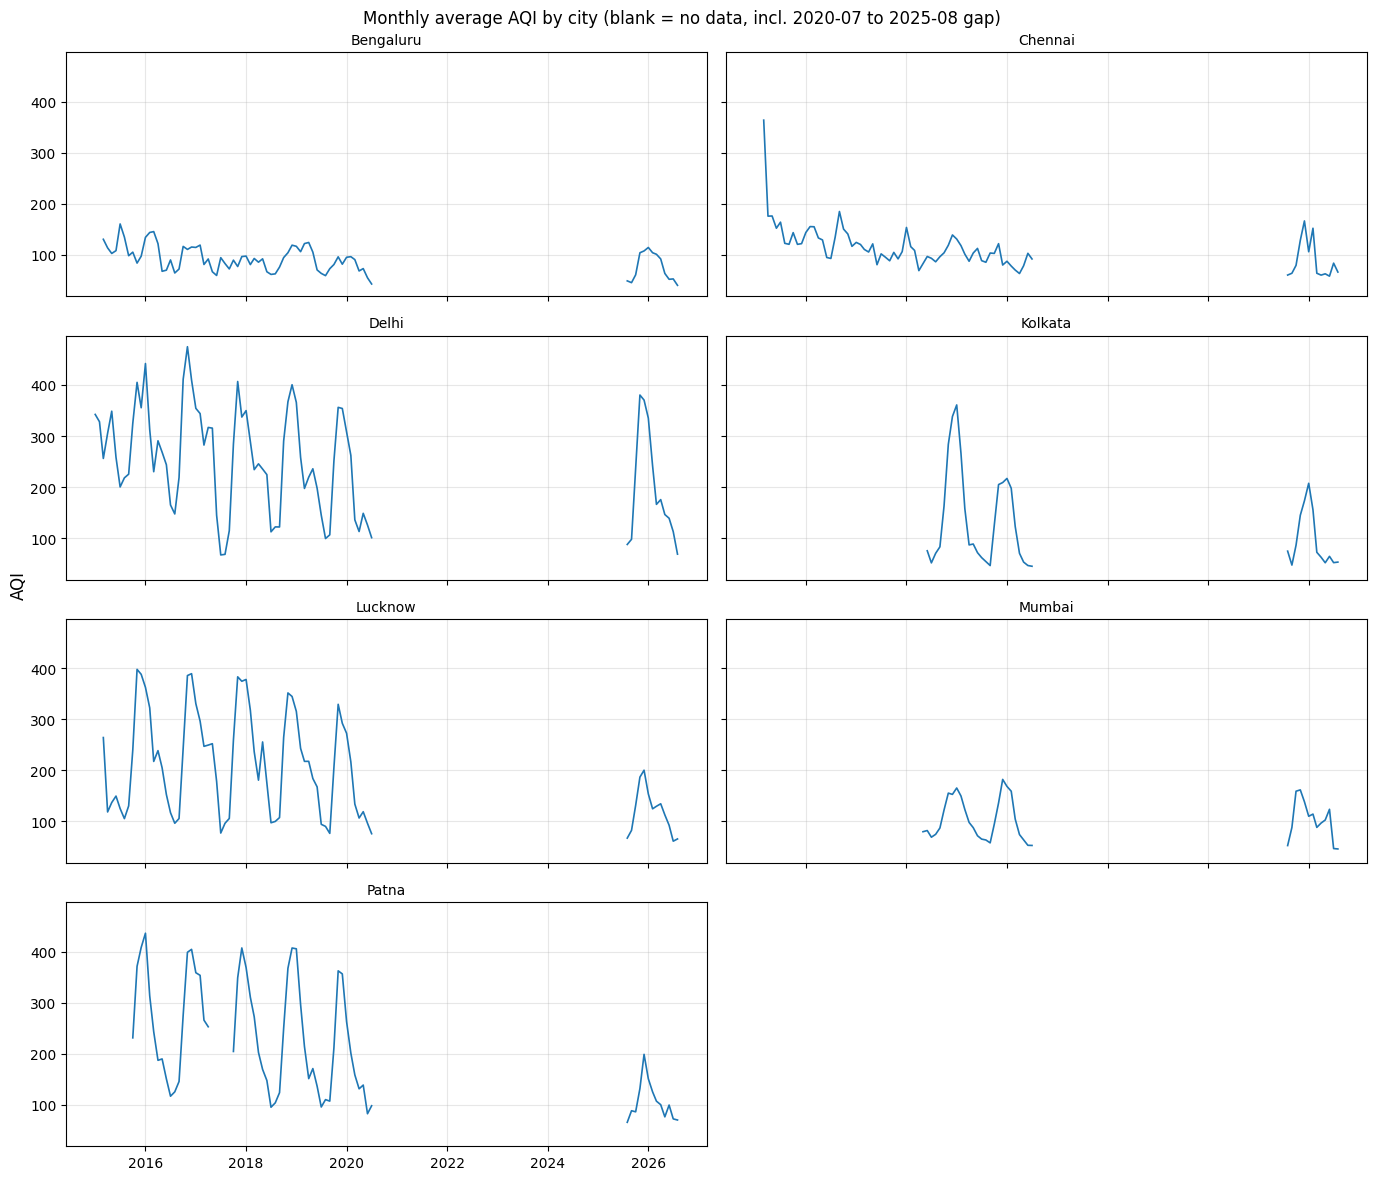

In [12]:
full_months = pd.date_range('2015-01-01', '2026-08-01', freq='MS')
pivot = (monthly_city.pivot(index='year_month', columns='city', values='AQI')
         .reindex(full_months))

fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True, sharey=True)
axes = axes.flatten()
for ax, city in zip(axes, pivot.columns):
    ax.plot(pivot.index, pivot[city], linewidth=1.2)
    ax.set_title(city, fontsize=10)
    ax.grid(alpha=0.3)
axes[-1].axis('off')
fig.suptitle('Monthly average AQI by city (blank = no data, incl. 2020-07 to 2025-08 gap)', fontsize=12)
fig.supylabel('AQI')
plt.tight_layout()
plt.savefig('reports/figures/01_monthly_aqi_by_city.png', dpi=150)
plt.show()

city  Bengaluru  Chennai  Delhi  Kolkata  Lucknow  Mumbai  Patna
year                                                            
2015      112.6    148.3  297.0      NaN    202.2     NaN    NaN
2016      105.6    138.6  301.4      NaN    243.0     NaN  252.3
2017       87.1    104.5  256.7      NaN    237.6     NaN    NaN
2018       86.3    105.5  249.2      NaN    233.8     NaN  233.6
2019       91.6    102.9  232.1    143.9    202.6   108.0  218.3


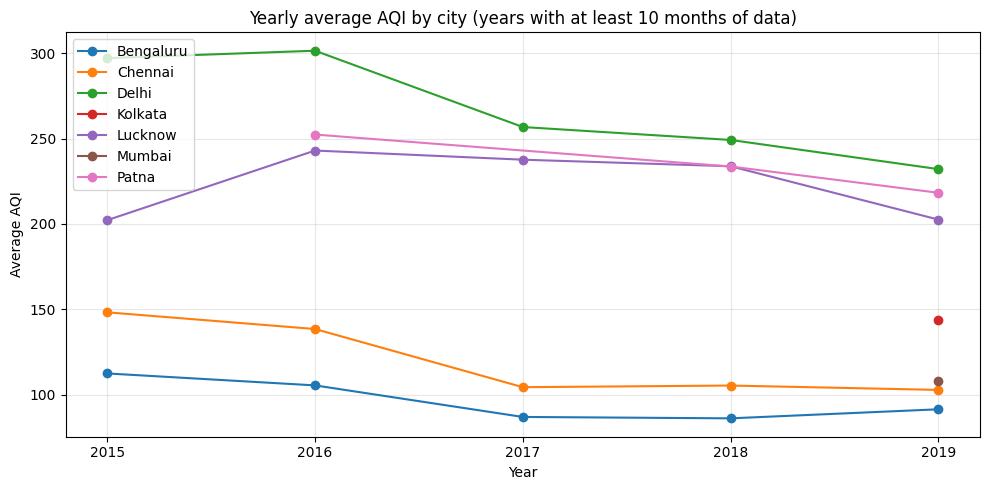

In [13]:
yearly = (master.groupby(['city', 'year'])
          .agg(avg_aqi=('AQI', 'mean'),
               months_with_data=('AQI', lambda x: master.loc[x.dropna().index, 'month'].nunique()))
          .reset_index())

# only keep years where the city has AQI for at least 10 of 12 months
yearly_full = yearly[yearly['months_with_data'] >= 10]
print(yearly_full.pivot(index='year', columns='city', values='avg_aqi').round(1))

fig, ax = plt.subplots(figsize=(10, 5))
for city, g in yearly_full.groupby('city'):
    ax.plot(g['year'], g['avg_aqi'], marker='o', label=city)
ax.set_title('Yearly average AQI by city (years with at least 10 months of data)')
ax.set_xlabel('Year'); ax.set_ylabel('Average AQI')
ax.set_xticks(sorted(yearly_full['year'].unique()))
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('reports/figures/02_yearly_trend.png', dpi=150)
plt.show()

city     Bengaluru  Chennai  Delhi  Kolkata  Lucknow  Mumbai  Patna
period                                                             
2015         112.6    148.3  297.0      NaN    202.2     NaN    NaN
2016         105.6    138.6  301.4      NaN    243.0     NaN  252.3
2017          87.1    104.5  256.7      NaN    237.6     NaN    NaN
2018          86.3    105.5  249.2      NaN    233.8     NaN  233.6
2019          91.6    102.9  232.1    143.9    202.6   108.0  218.3
2025-26       78.1     89.8  207.1     96.5    122.5   106.7  107.3


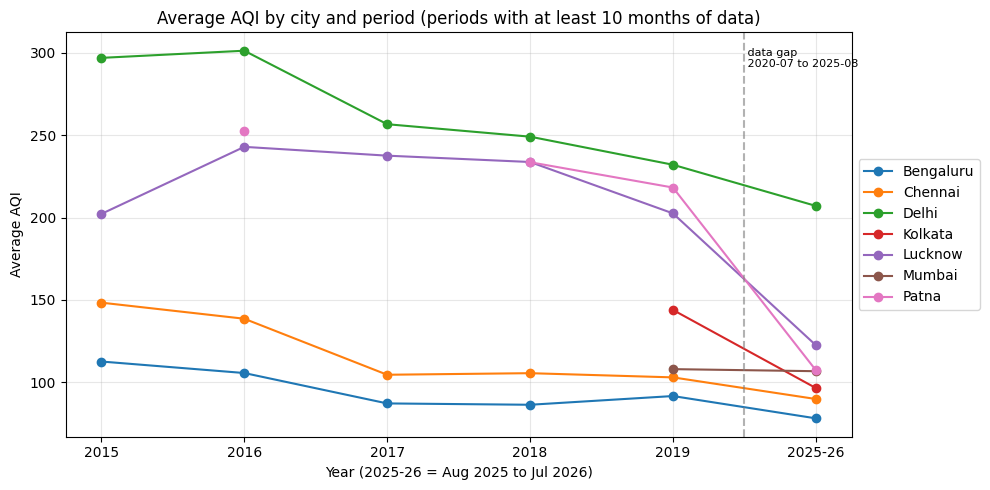

In [15]:
d = master[master['date'] < '2026-08-01'].copy()   # drop the 10 stray days of Aug 2026

d['period'] = d['year'].astype(str)
rec = d['data_source'] == 'openaq_recent'
d.loc[rec, 'period'] = np.where(d.loc[rec, 'month'] >= 8,
                                d.loc[rec, 'year'], d.loc[rec, 'year'] - 1).astype(int).astype(str)
d.loc[rec, 'period'] = d.loc[rec, 'period'].map(lambda y: f"{y}-{str(int(y)+1)[2:]}")

valid = d.dropna(subset=['AQI']).copy()
valid['ym'] = valid['date'].dt.to_period('M')

period_stats = (valid.groupby(['city', 'period'])
                .agg(avg_aqi=('AQI', 'mean'), months=('ym', 'nunique'))
                .reset_index())
period_stats = period_stats[period_stats['months'] >= 10]

order = ['2015', '2016', '2017', '2018', '2019', '2025-26']
tbl = period_stats.pivot(index='period', columns='city', values='avg_aqi').reindex(order)
print(tbl.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
for city in tbl.columns:
    ax.plot(order, tbl[city].values, marker='o', label=city)
ax.axvline(4.5, color='grey', linestyle='--', alpha=0.6)
ax.text(4.5, ax.get_ylim()[1]*0.97, ' data gap\n 2020-07 to 2025-08', fontsize=8, va='top')
ax.set_title('Average AQI by city and period (periods with at least 10 months of data)')
ax.set_xlabel('Year (2025-26 = Aug 2025 to Jul 2026)'); ax.set_ylabel('Average AQI')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5)); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('reports/figures/02_yearly_trend.png', dpi=150)
plt.show()

             Mon    Tue    Wed    Thu    Fri    Sat    Sun
city                                                      
Bengaluru   90.1   92.7   91.2   89.9   91.4   93.1   92.3
Chennai    105.5  109.2  111.5  113.8  112.7  110.0  109.8
Delhi      246.0  248.1  250.5  253.5  254.6  252.6  249.0
Kolkata    121.9  127.8  127.8  127.6  126.6  124.4  124.3
Lucknow    201.0  205.2  205.6  203.0  200.1  198.3  202.9
Mumbai     106.8  106.3  103.6  102.8  105.2  105.9  106.2
Patna      208.7  216.0  216.7  217.8  215.1  209.8  212.7

Average % difference from a city's overall mean AQI:
Mon   -1.78
Tue    0.60
Wed    0.52
Thu    0.54
Fri    0.52
Sat   -0.32
Sun   -0.10
dtype: float64


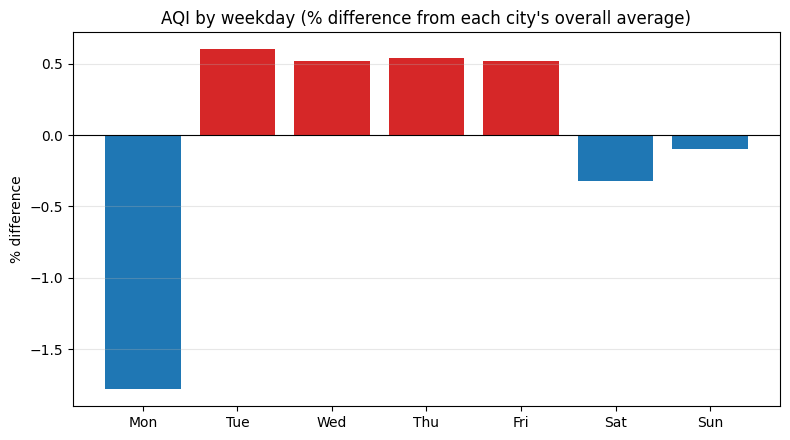

In [16]:
names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
v = master.dropna(subset=['AQI']).copy()

wd = v.groupby(['city', 'day_of_week'])['AQI'].mean().unstack()
wd.columns = names
print(wd.round(1))
print()

# weekday average as a % difference from each city's own overall average, then averaged across cities
rel = wd.div(v.groupby('city')['AQI'].mean(), axis=0)
pct = ((rel.mean() - 1) * 100).round(2)
print("Average % difference from a city's overall mean AQI:")
print(pct)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(names, pct.values, color=['#d62728' if x > 0 else '#1f77b4' for x in pct.values])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('AQI by weekday (% difference from each city\'s overall average)')
ax.set_ylabel('% difference')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('reports/figures/03_weekday_pattern.png', dpi=150)
plt.show()